

# Task no 1     Dataset Loading and Initial View:




In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv("titanic.csv")

In [3]:
df.head(7)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S


In [4]:
df.shape # to check no of rows and columns .

(891, 12)

In [5]:
# another method to display no of rows and columns
print("Total rows:", len(df))

Total rows: 891


In [6]:
print("Total Columns:", len(df.columns))

Total Columns: 12


 # Task no 2   Data Exploration:

In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [9]:
Numerical_variables = df.select_dtypes(include='number').columns
print(Numerical_variables.tolist())

['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


In [10]:
Categorical_variables=df.select_dtypes(include='str').columns
print( "Categorical_variables\n",Categorical_variables.tolist())

Categorical_variables
 ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [11]:
df["Sex"].unique().tolist()       

['male', 'female']

In [12]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [13]:
df["Pclass"].unique()

array([3, 1, 2])

In [14]:
df["Pclass"].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [15]:
print("Unique values in Sex:", df['Sex'].unique().tolist())    #  2nd method with print()  it is good practice
print("Number of unique values:", df['Sex'].nunique())

Unique values in Sex: ['male', 'female']
Number of unique values: 2


In [16]:
   print("Unique values in Pclass:", df['Pclass'].unique())
   print("Number of Unique values in Pclass:", df['Pclass'].nunique())

Unique values in Pclass: [3 1 2]
Number of Unique values in Pclass: 3


In [17]:
print("Frequency Distribution:", df['Sex'].value_counts())

Frequency Distribution: Sex
male      577
female    314
Name: count, dtype: int64


In [18]:
print("Frequency Distribution:", df['Pclass'].value_counts())

Frequency Distribution: Pclass
3    491
1    216
2    184
Name: count, dtype: int64


# Task no 3 Data Preprocessing 

In [19]:
df.isnull().sum()        # to check missing values

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
df = df.drop(columns=['Cabin'])

Age is not filled yet. It will be filled after the train/test split using the train median (to avoid data leakage).

In [21]:
# Embarked is categorical, so median/mean can't be used. Filled with the mode (most frequent value).
# Note: mode is calculated on the full dataset (only 2 missing values, so the impact is negligible).
# Ideally, it should be filled after the train/test split using the train mode, like Age.
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [22]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
dtype: int64

# Task no 4: Feature Selection & Encoding
SVC (Support Vector Classifier) just work on numbers, not on string. so convert Sex aur Embarked into numbers

In [23]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()   # independent features or variables
y = df['Survived']                                                         # dependent/target variable 

In [24]:
# Sex: male=0, female=1
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})       # numerical encoding

In [25]:
# Embarked: One-Hot Encoding
X = pd.get_dummies(X, columns=['Embarked'], drop_first=True)   # one-hot coding is generally best for unordered categories 

In [26]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,False,True
1,1,1,38.0,1,0,71.2833,False,False
2,3,1,26.0,0,0,7.9250,False,True
3,1,1,35.0,1,0,53.1000,False,True
4,3,0,35.0,0,0,8.0500,False,True


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [28]:
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (712, 8)
Testing set size: (179, 8)


In [29]:
# Age is numerical, so we fill it with the median instead of the mean.
# Median is not affected by extreme values (outliers), so it is a safer choice.

age_median = X_train['Age'].median() 
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [31]:
from sklearn.svm import SVC

In [32]:
model = SVC()

In [33]:
model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [34]:
y_pred = model.predict(X_test)

In [35]:
y_pred

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 1])

In [36]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8212290502793296


In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[95 10]
 [22 52]]


In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.8387096774193549
Recall: 0.7027027027027027
F1-score: 0.7647058823529411


In [39]:
from sklearn.metrics import classification_report   # other and simple method. i think it is better than above.less time taking
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.90      0.86       105
           1       0.84      0.70      0.76        74

    accuracy                           0.82       179
   macro avg       0.83      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



Task no 5:    Data Visualization

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

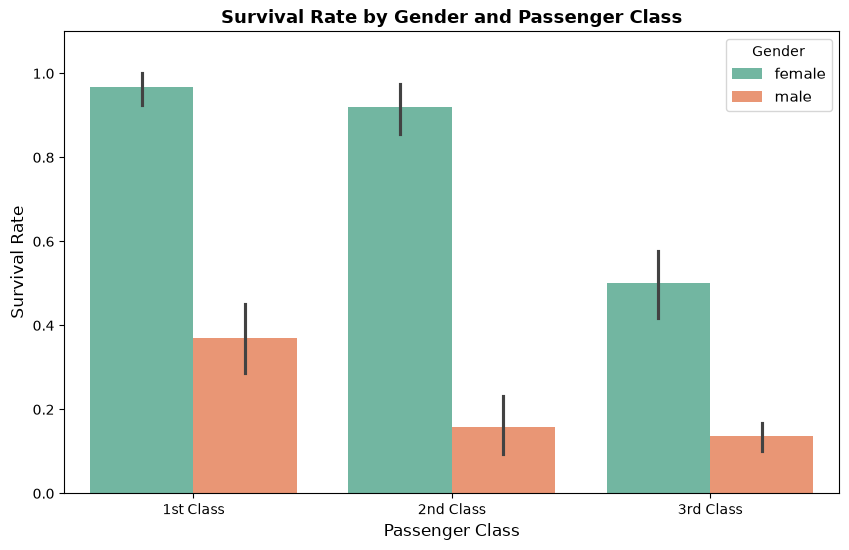

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='Set2')

plt.title('Survival Rate by Gender and Passenger Class', fontsize=13, fontweight='bold')
plt.xlabel('Passenger Class', fontsize=12)
plt.ylabel('Survival Rate', fontsize=12)
plt.xticks([0, 1, 2], ['1st Class', '2nd Class', '3rd Class'])
plt.legend(title='Gender', fontsize=11)
plt.ylim(0, 1.1)
plt.show()

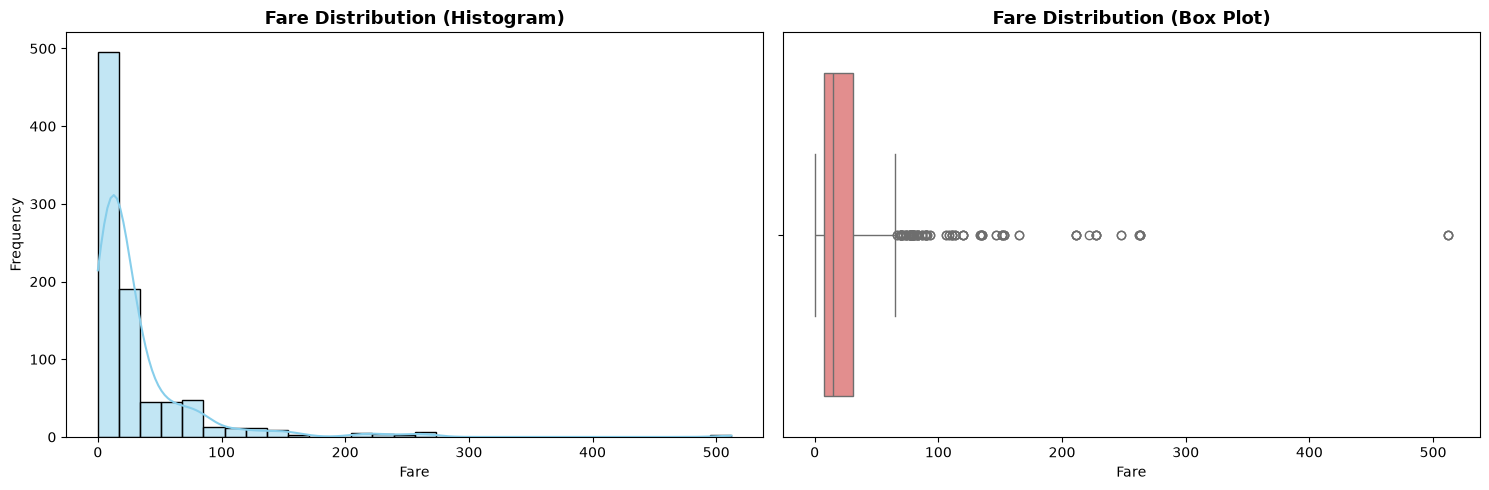

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
sns.histplot(df['Fare'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Fare Distribution (Histogram)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Fare')
axes[0].set_ylabel('Frequency')

# Box Plot
sns.boxplot(x=df['Fare'], ax=axes[1], color='lightcoral')
axes[1].set_title('Fare Distribution (Box Plot)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Fare')

plt.tight_layout()
plt.show()

In [43]:
print("Fare Skewness:", df['Fare'].skew())
print("Mean:", df['Fare'].mean())
print("Median:", df['Fare'].median())

Fare Skewness: 4.787316519674893
Mean: 32.204207968574636
Median: 14.4542


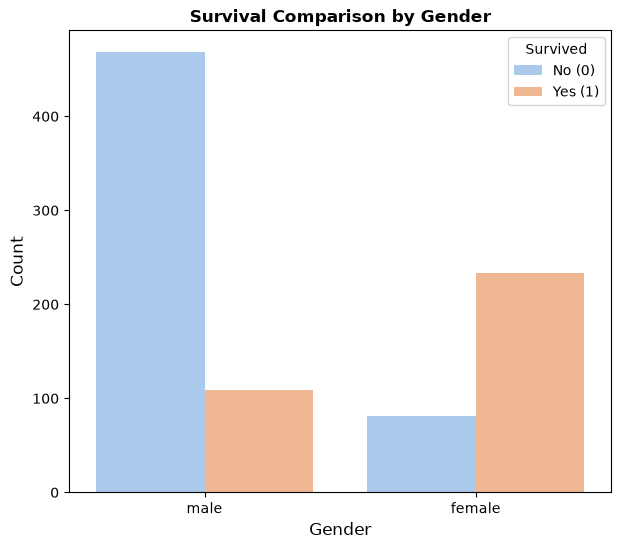

In [44]:
plt.figure(figsize=(7, 6))

sns.countplot(data=df, x='Sex', hue='Survived', palette='pastel')   # pastel light color deta h 

plt.title('Survival Comparison by Gender', fontsize=12, fontweight='bold')
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(title='Survived', labels=['No (0)', 'Yes (1)'])
plt.show()

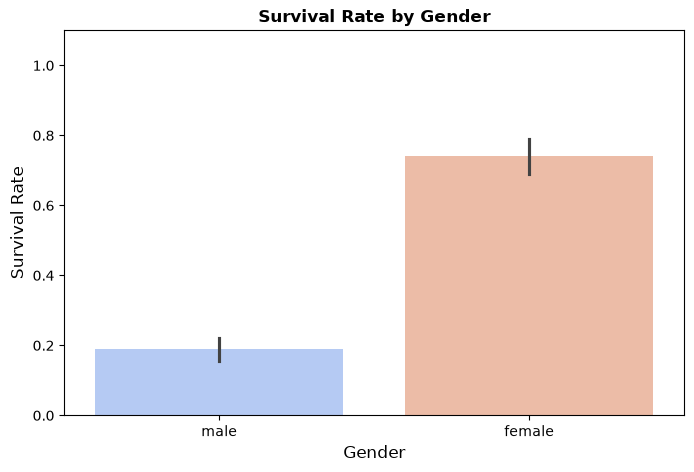

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='Sex', y='Survived', hue= 'Sex',palette='coolwarm')

plt.title('Survival Rate by Gender', fontsize=12, fontweight='bold')
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Survival Rate', fontsize=12)
plt.ylim(0, 1.1)
plt.show()

In [46]:
print(df.groupby('Sex')['Survived'].mean())

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


In [47]:
pd.crosstab(df['Sex'], df['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [48]:
print(df['Survived'].value_counts())
print(df['Sex'].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64
Sex
male      577
female    314
Name: count, dtype: int64
